***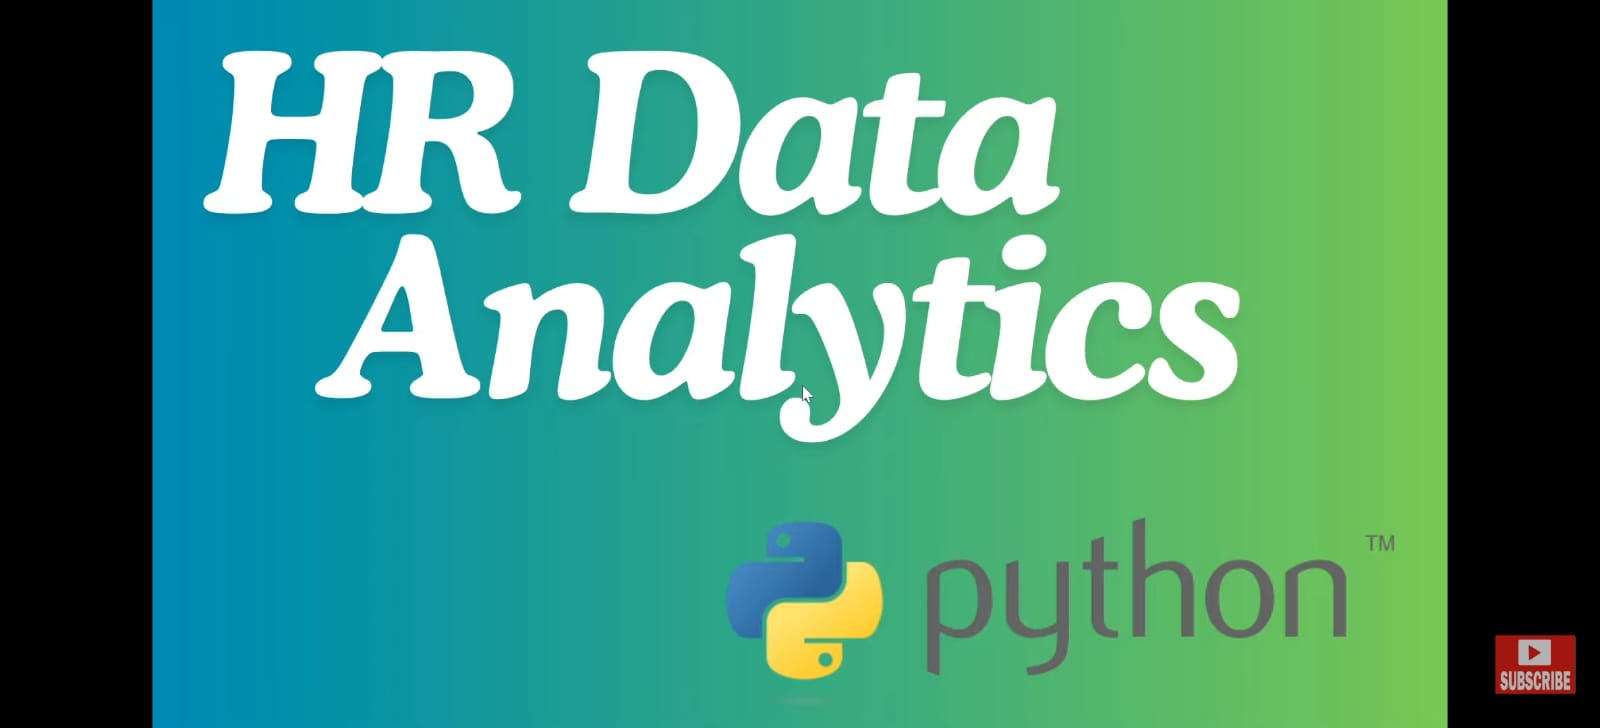***




In [31]:

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


In [32]:
from google.colab import files

uploaded= files.upload()

Saving HR_Data.xlsx to HR_Data (1).xlsx


In [33]:
df = pd.read_excel("HR_Data.xlsx")

df.head()

,Unnamed: 0,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686
2,2,EMP0000003,Alyssa Martinez,HR,HR Manager,2023-03-20,"Port Christinaport, Saudi Arabia",1,2,Active,On-site,1430084
3,3,EMP0000004,Nicholas Valdez,IT,Software Engineer,2023-10-12,"Port Shelbychester, Antigua and Barbuda",1,1,Active,On-site,990689
4,4,EMP0000005,Joel Hendricks,Operations,Logistics Coordinator,2024-12-09,"Lake Kimberly, Palestinian Territory",5,0,Active,On-site,535082


In [34]:
# getting basic information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 12 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   Unnamed: 0          1048575 non-null  int64         
 1   Employee_ID         1048575 non-null  object        
 2   Full_Name           1048575 non-null  object        
 3   Department          1048575 non-null  object        
 4   Job_Title           1048575 non-null  object        
 5   Hire_Date           1048575 non-null  datetime64[ns]
 6   Location            1048575 non-null  object        
 7   Performance_Rating  1048575 non-null  int64         
 8   Experience_Years    1048575 non-null  int64         
 9   Status              1048575 non-null  object        
 10  Work_Mode           1048575 non-null  object        
 11  Salary_INR          1048575 non-null  int64         
dtypes: datetime64[ns](1), int64(4), object(7)
memory usage: 96.0+ MB


In [35]:
# removing unwanted colunm from the data frame

data=df.drop("Unnamed: 0",axis=1,inplace= True)

In [36]:
# change date formate

df['Hire_Date']=pd.to_datetime(df['Hire_Date'])

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   Employee_ID         1048575 non-null  object        
 1   Full_Name           1048575 non-null  object        
 2   Department          1048575 non-null  object        
 3   Job_Title           1048575 non-null  object        
 4   Hire_Date           1048575 non-null  datetime64[ns]
 5   Location            1048575 non-null  object        
 6   Performance_Rating  1048575 non-null  int64         
 7   Experience_Years    1048575 non-null  int64         
 8   Status              1048575 non-null  object        
 9   Work_Mode           1048575 non-null  object        
 10  Salary_INR          1048575 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(7)
memory usage: 88.0+ MB


In [38]:
df['Performance_Rating'].unique()

array([5, 2, 1, 4, 3])

In [39]:
df['Performance_Rating'].value_counts()

,count
Performance_Rating,
4,210152
2,209954
1,209559
3,209485
5,209425


In [40]:
df['Performance_Rating'].mean()

np.float64(2.999933242734187)

In [41]:
df['Experience_Years'].unique()

array([14,  7,  2,  1,  0,  4,  9,  5,  6,  8,  3, 10, 11, 12, 13, 15])

In [42]:
df['Experience_Years'].value_counts()

,count
Experience_Years,
3,105251
1,104630
4,104539
2,104444
0,104411
5,84071
9,83993
6,83930
8,83857


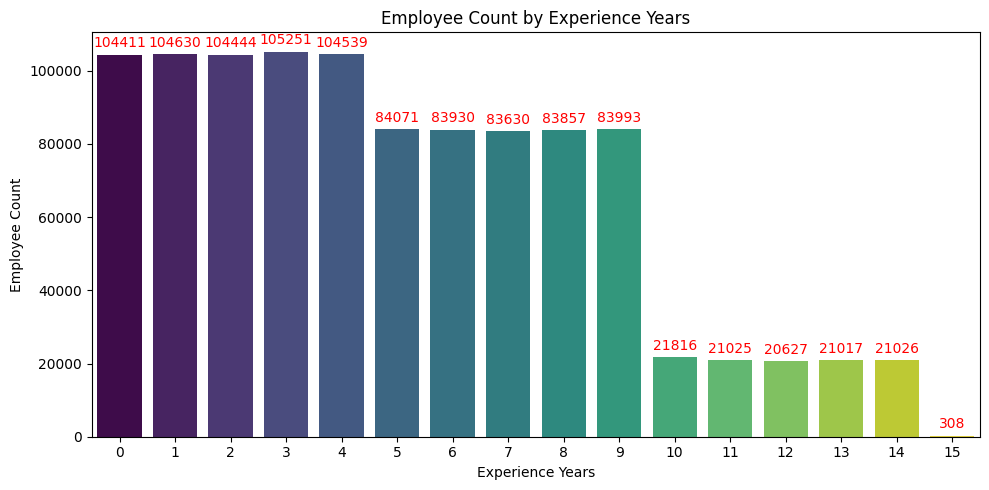

In [63]:
plt.figure(figsize=(10, 5))

ax = sns.countplot(
    x='Experience_Years',
    hue='Experience_Years',
    data=df,
    palette='viridis',
    legend=False)

# Add employee count labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        padding=3,
        fontsize=10,
        color='red',
    )

plt.title('Employee Count by Experience Years')
plt.xlabel('Experience Years')
plt.ylabel('Employee Count')

plt.tight_layout()
plt.show()

In [64]:
# consider the column having data type "object" only

df.select_dtypes(include="object")

,Employee_ID,Full_Name,Department,Job_Title,Location,Status,Work_Mode
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,"Isaacland, Denmark",Resigned,On-site
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,"Anthonyside, Costa Rica",Active,On-site
2,EMP0000003,Alyssa Martinez,HR,HR Manager,"Port Christinaport, Saudi Arabia",Active,On-site
3,EMP0000004,Nicholas Valdez,IT,Software Engineer,"Port Shelbychester, Antigua and Barbuda",Active,On-site
4,EMP0000005,Joel Hendricks,Operations,Logistics Coordinator,"Lake Kimberly, Palestinian Territory",Active,On-site
...,...,...,...,...,...,...,...
1048570,EMP1048571,Jason Rich,IT,Software Engineer,"Hernandezmouth, Albania",Active,On-site
1048571,EMP1048572,Keith Olson,Sales,Sales Executive,"Marystad, Anguilla",Active,On-site
1048572,EMP1048573,Lauren Becker,HR,Talent Acquisition Specialist,"Beckburgh, Israel",Active,On-site
1048573,EMP1048574,James Sims,Operations,Supply Chain Manager,"New William, Zambia",Active,On-site


In [65]:
# consider the column having data type "int" only

df.select_dtypes(include="int")

,Performance_Rating,Experience_Years,Salary_INR
0,5,14,1585363
1,2,7,847686
2,1,2,1430084
3,1,1,990689
4,5,0,535082
...,...,...,...
1048570,1,0,648143
1048571,3,4,401046
1048572,4,1,1120701
1048573,2,3,534552


In [66]:
# Q.1) What is the distribution of Employee Status (Active, Resigned, Retired, Terminated)?

df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [74]:
Status = df['Status'].value_counts()
Status

,count
Status,
Active,734439
Resigned,209342
Retired,52462
Terminated,52332


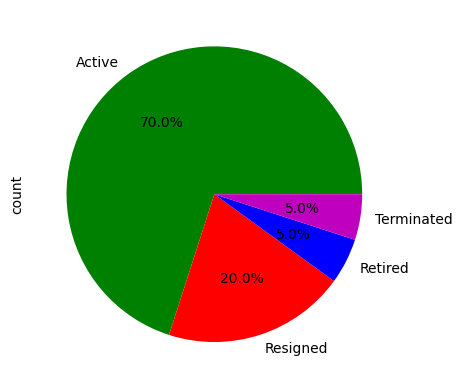

In [80]:
Status.plot(kind="pie",colors="grbm",autopct='%1.1f%%')

plt.show()

In [81]:
#Q.2) What is the distribution of work modes (On-site, Remote)?

df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [84]:
work=df['Work_Mode'].value_counts()
work

,count
Work_Mode,
On-site,628436
Remote,420139


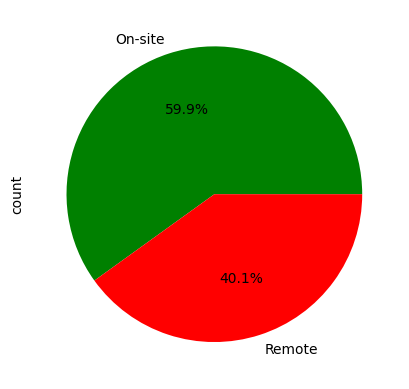

In [85]:
work.plot(kind="pie",colors="gr",autopct='%1.1f%%')

plt.show()

In [86]:
# Q.2) How many employees are there in each department?
df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [88]:
dep_count = df['Department'].value_counts()
dep_count

,count
Department,
IT,315028
Sales,209524
Operations,157513
Marketing,126113
Finance,104722
HR,83484
R&D,52191


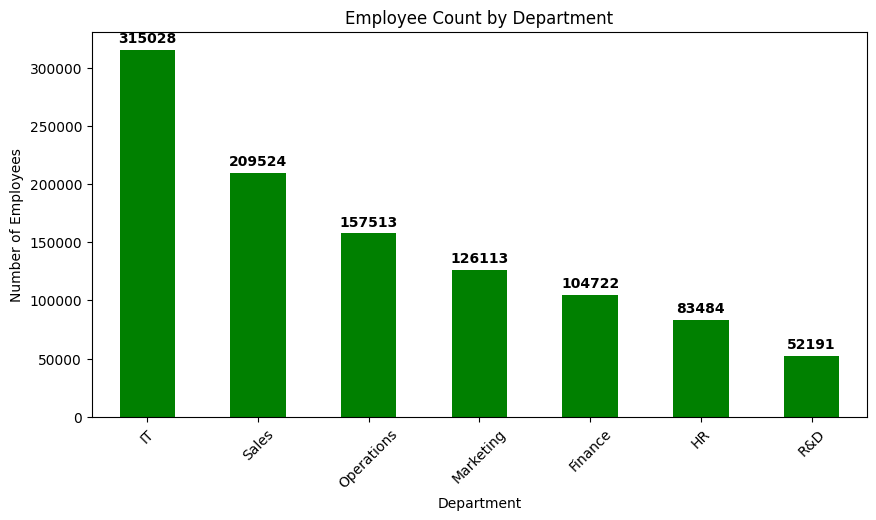

In [98]:
ax = dep_count.plot(
    kind="bar",
    figsize=(10, 5),
    color="g"
)

# Add data labels
ax.bar_label(ax.containers[0], padding=3, fontsize=10, fontweight="bold")

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()

In [102]:
Job_title_count = df['Job_Title'].value_counts()
Job_title_count

,count
Job_Title,
Software Engineer,157480
Sales Executive,104690
Operations Executive,78582
Marketing Executive,63138
Account Manager,63009
Data Analyst,62899
Accountant,52487
Logistics Coordinator,47355
DevOps Engineer,47193


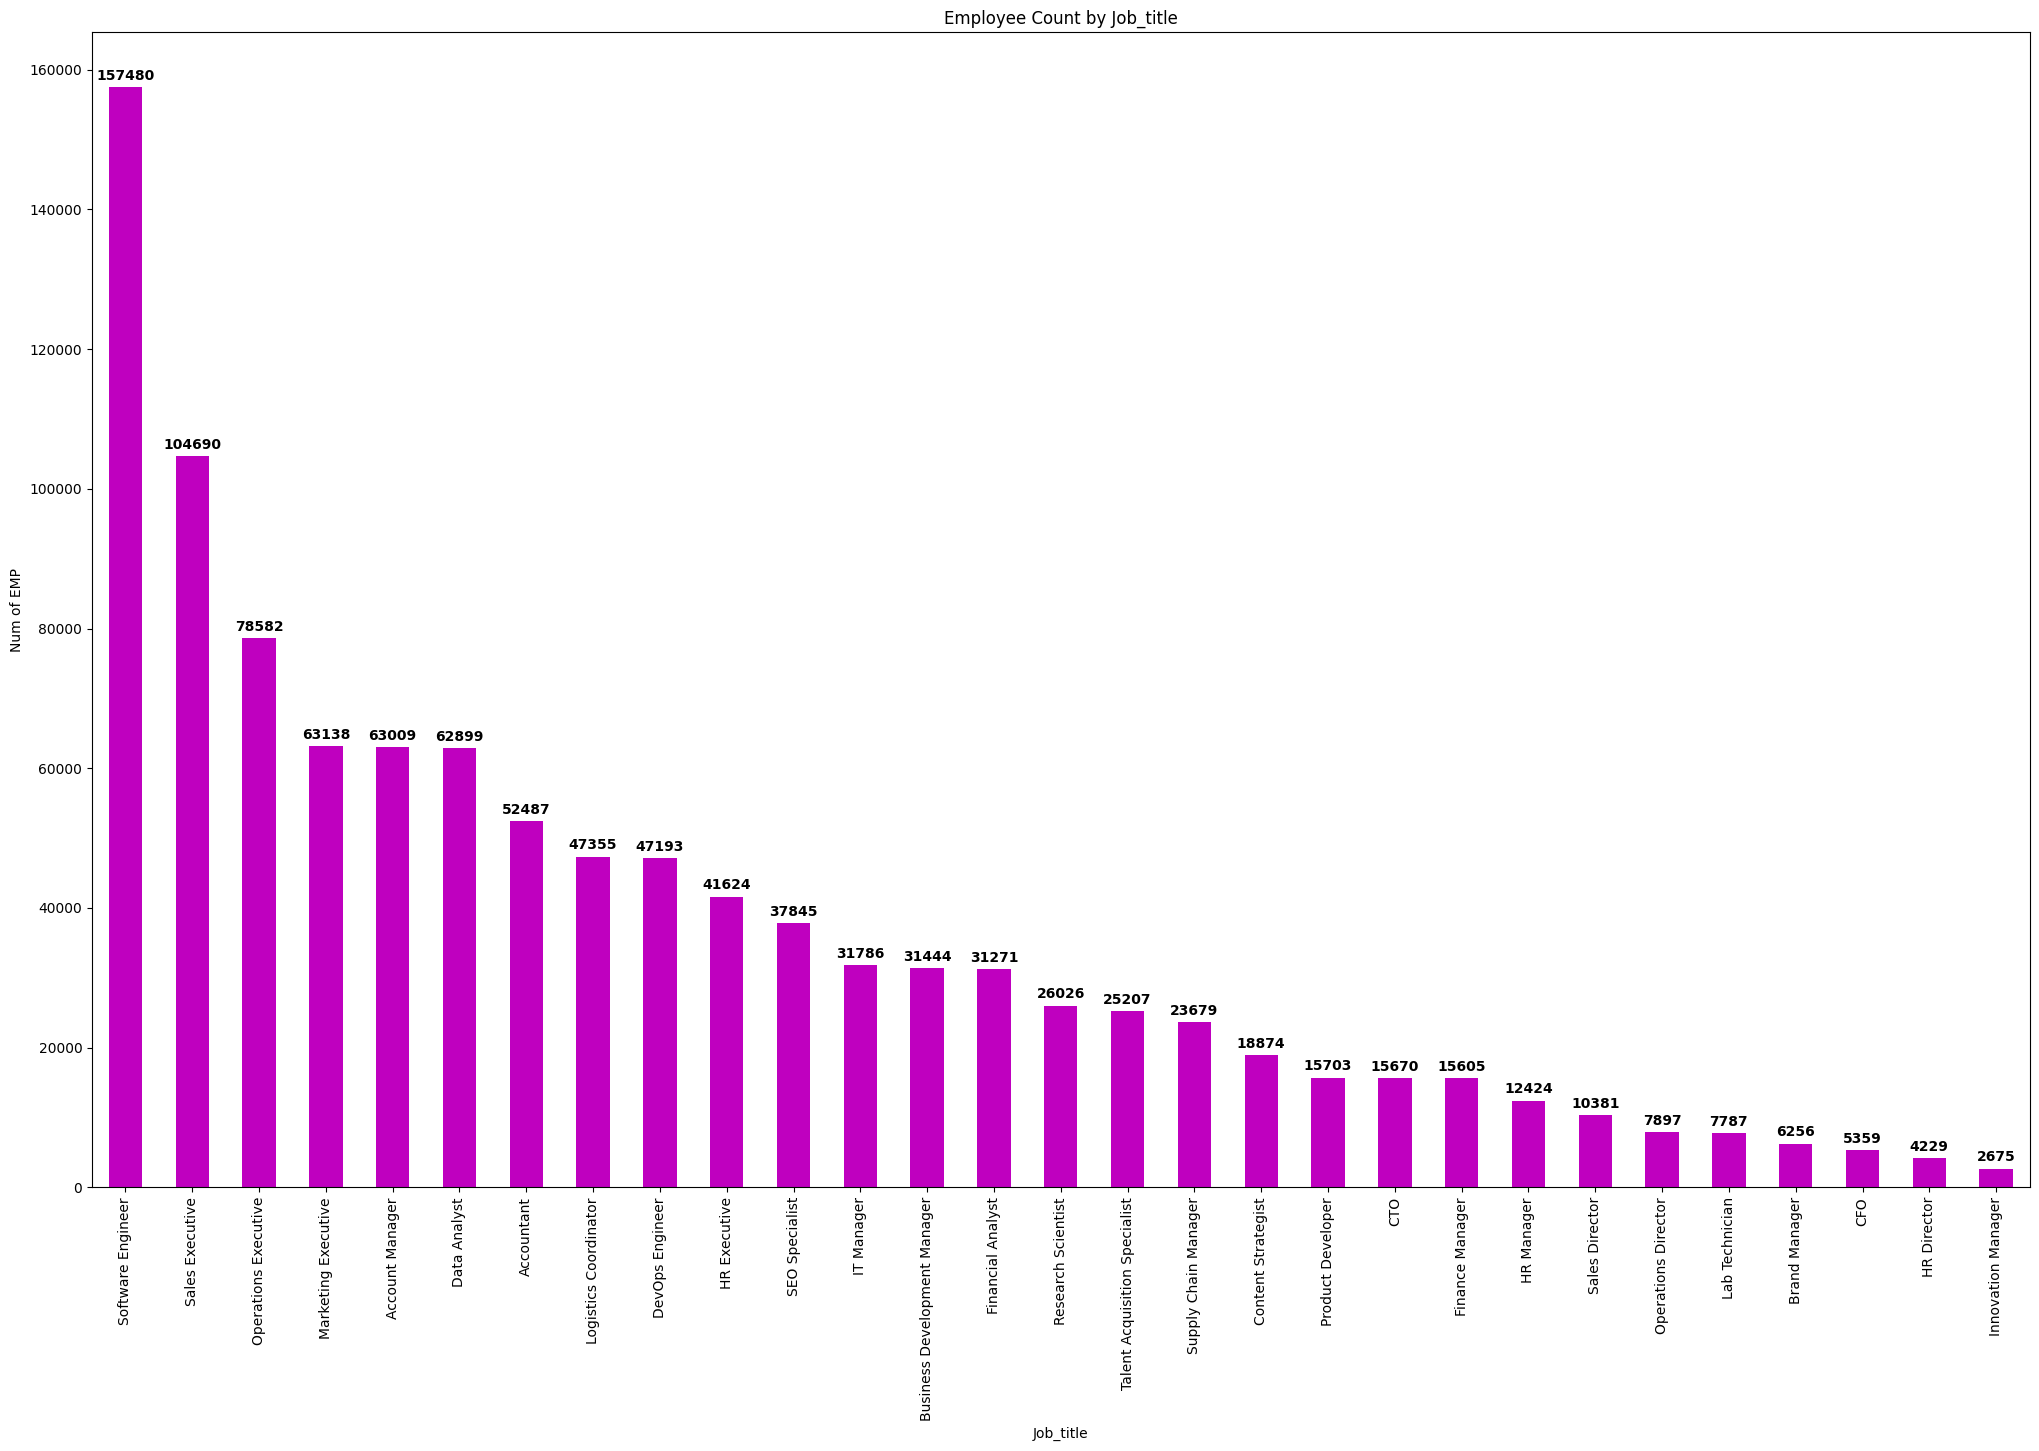

In [112]:
ax = Job_title_count.plot(
    kind="bar",
    figsize=(25,15),
    color="m"
)

# Add data labels
ax.bar_label(ax.containers[0], padding=3, fontsize=10, fontweight="bold")

plt.title("Employee Count by Job_title")
plt.xlabel("Job_title")
plt.ylabel("Num of EMP")
plt.xticks(rotation=90)
plt.show()

In [113]:
# Q.3) What is the average salary by Department?

df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [125]:
dept_sly=df.groupby('Department')['Salary_INR'].mean()/100
dept_sly

,Salary_INR
Department,
Finance,9404.825371
HR,7429.245867
IT,11304.798317
Marketing,7698.197620
Operations,7546.911287
R&D,8005.640671
Sales,7926.011382


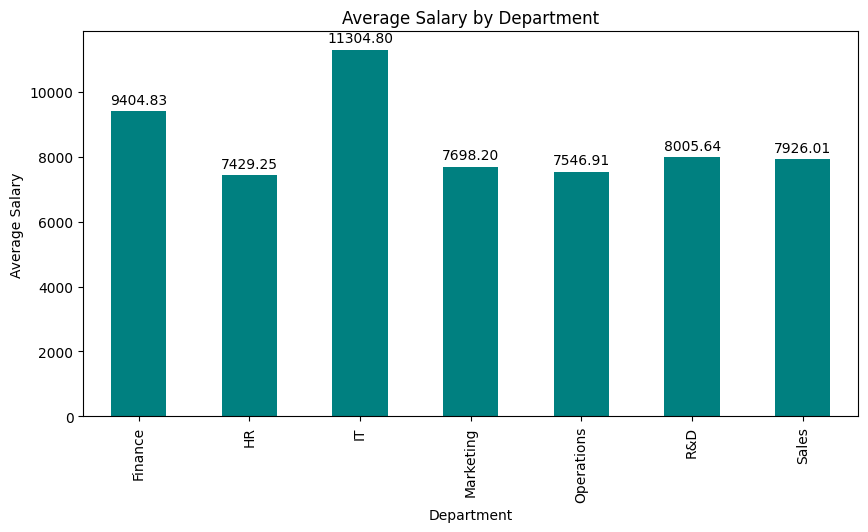

In [127]:
ax = dept_sly.plot(
    kind="bar",
    color="teal",
    figsize=(10, 5)
)

# Add data labels
ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
    fontsize=10)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.show()

In [128]:
#Q.5) Which job title has the highest average salary?
df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [129]:
Job_title_sly=df.groupby('Job_Title')['Salary_INR'].mean()/100
Job_title_sly

,Salary_INR
Job_Title,
Account Manager,8000.250519
Accountant,6502.466797
Brand Manager,8024.260919
Business Development Manager,12511.372891
CFO,7966.929974
CTO,8015.820743
Content Strategist,8018.396124
Data Analyst,8001.303965
DevOps Engineer,8004.794513


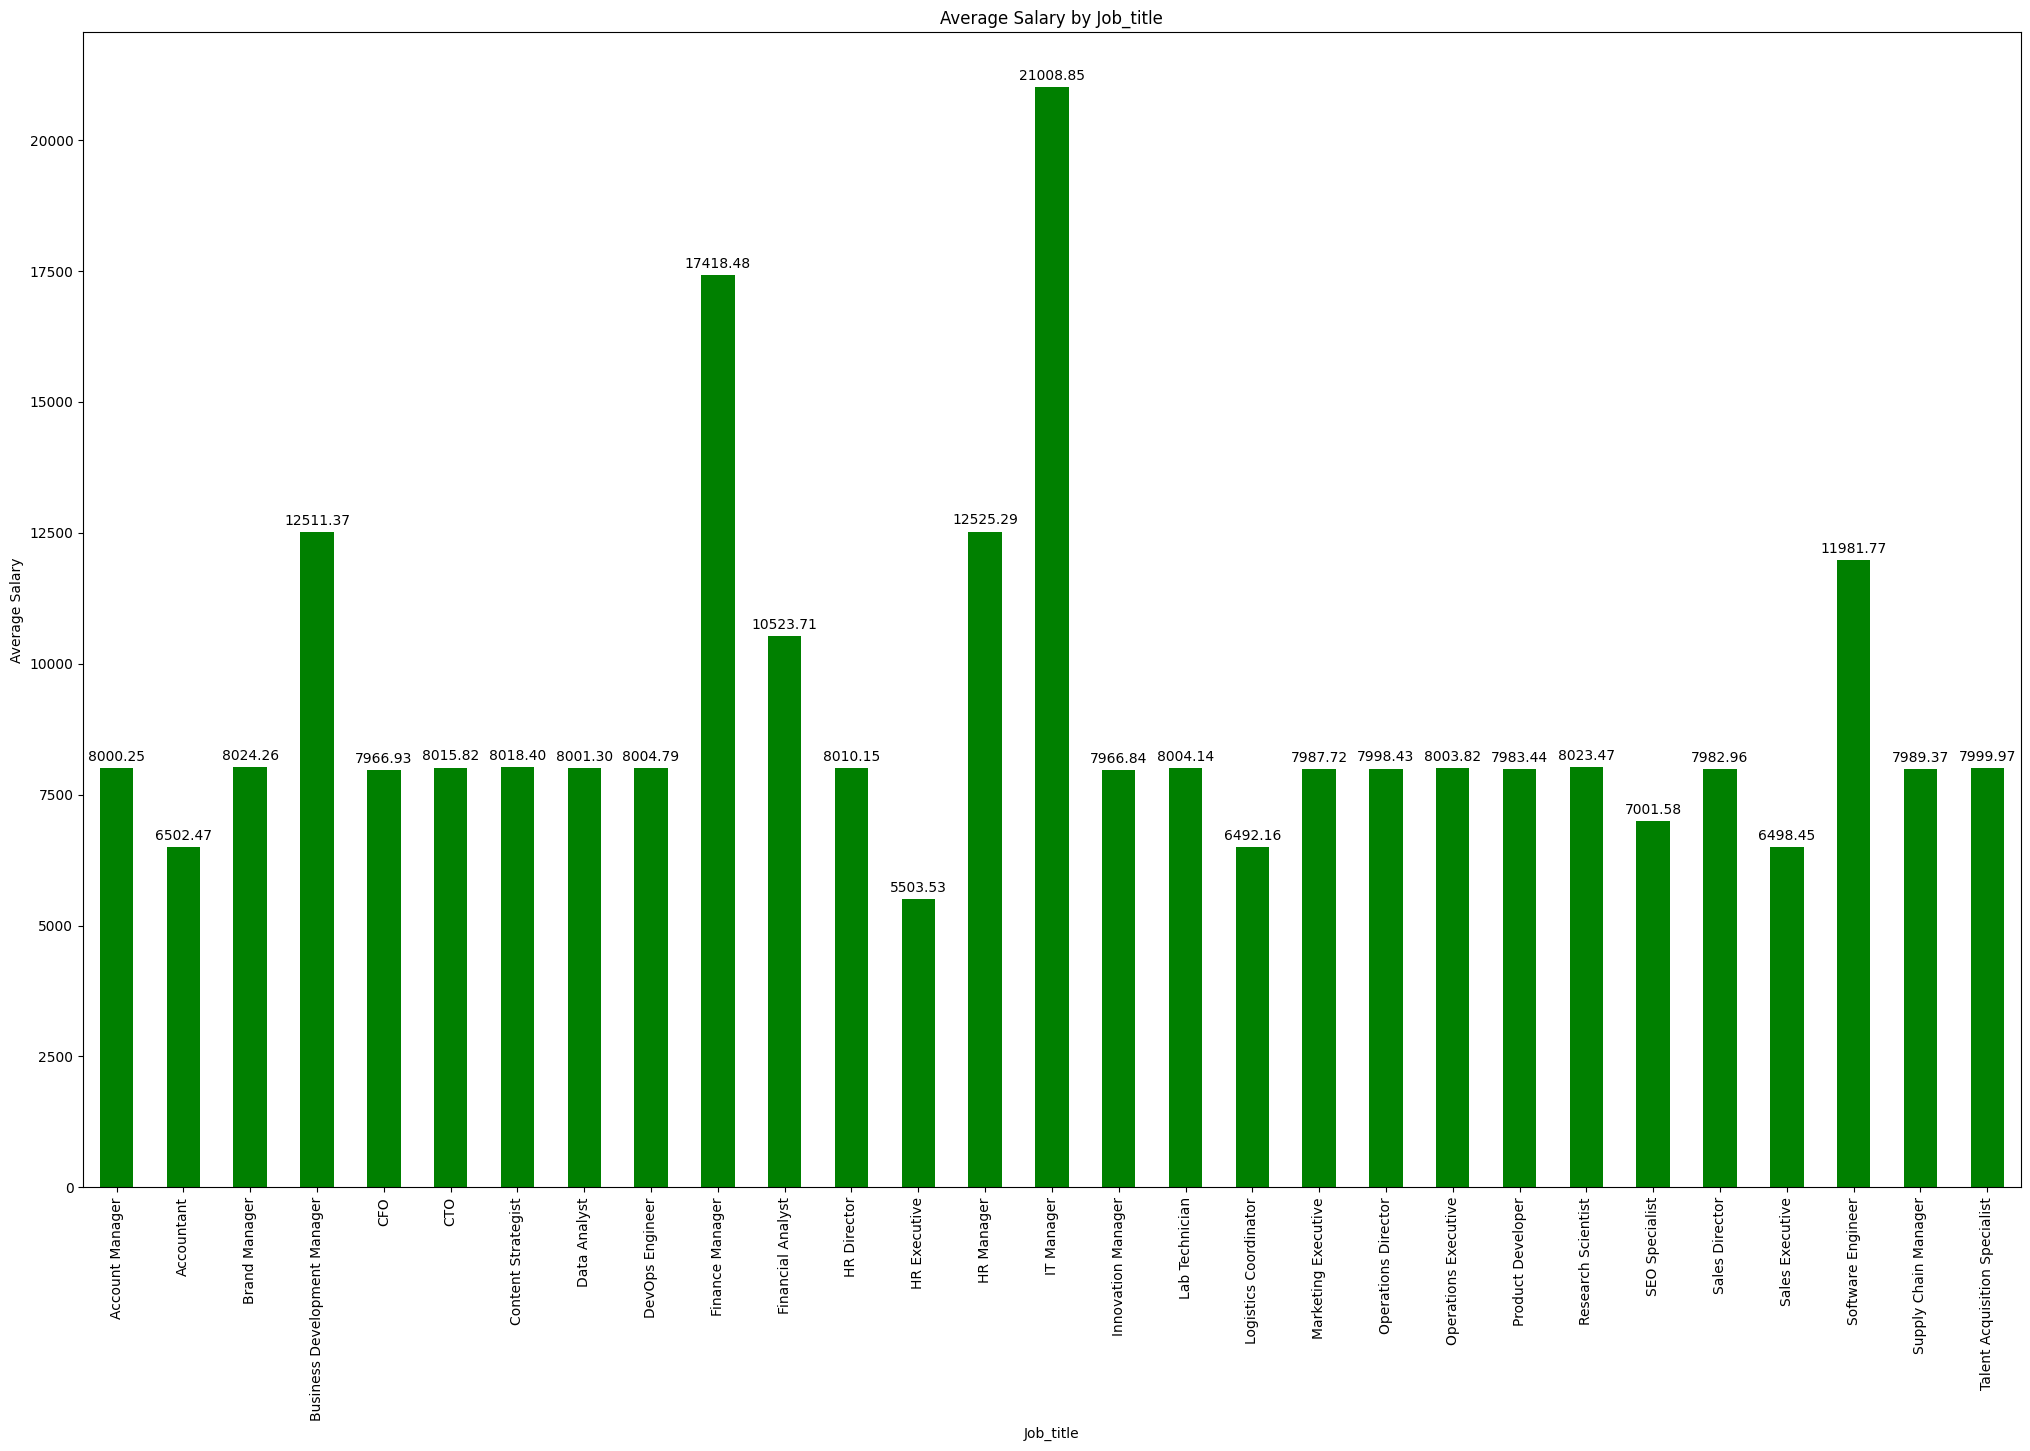

In [132]:
ax = Job_title_sly.plot(
    kind="bar",
    color="g",
    figsize=(25,15)
)

# Add data labels
ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
    fontsize=10)

plt.title("Average Salary by Job_title")
plt.xlabel("Job_title")
plt.ylabel("Average Salary")
plt.show()

In [135]:
#Q.6) What is the average salary in different Departments based on Job Title?

df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [145]:
dept_job_title = df.groupby(['Department','Job_Title'])['Salary_INR'].mean()/100

dept_job_title

Department  Job_Title                    
Finance     Accountant                        6502.466797
            CFO                               7966.929974
            Finance Manager                  17418.481835
            Financial Analyst                10523.710818
HR          HR Director                       8010.148610
            HR Executive                      5503.530831
            HR Manager                       12525.285844
            Talent Acquisition Specialist     7999.965280
IT          CTO                               8015.820743
            Data Analyst                      8001.303965
            DevOps Engineer                   8004.794513
            IT Manager                       21008.850827
            Software Engineer                11981.765781
Marketing   Brand Manager                     8024.260919
            Content Strategist                8018.396124
            Marketing Executive               7987.722734
            SEO Specialist                    7001.584719
Operations  Logistics Coordinator             6492.163940
            Operations Director               7998.432564
            Operations Executive              8003.822825
            Supply Chain Manager              7989.365559
R&D         Innovation Manager                7966.839716
            Lab Technician                    8004.137242
            Product Developer                 7983.439254
            Research Scientist                8023.473939
Sales       Account Manager                   8000.250519
            Business Development Manager     12511.372891
            Sales Director                    7982.964561
            Sales Executive                   6498.453142
Name: Salary_INR, dtype: float64

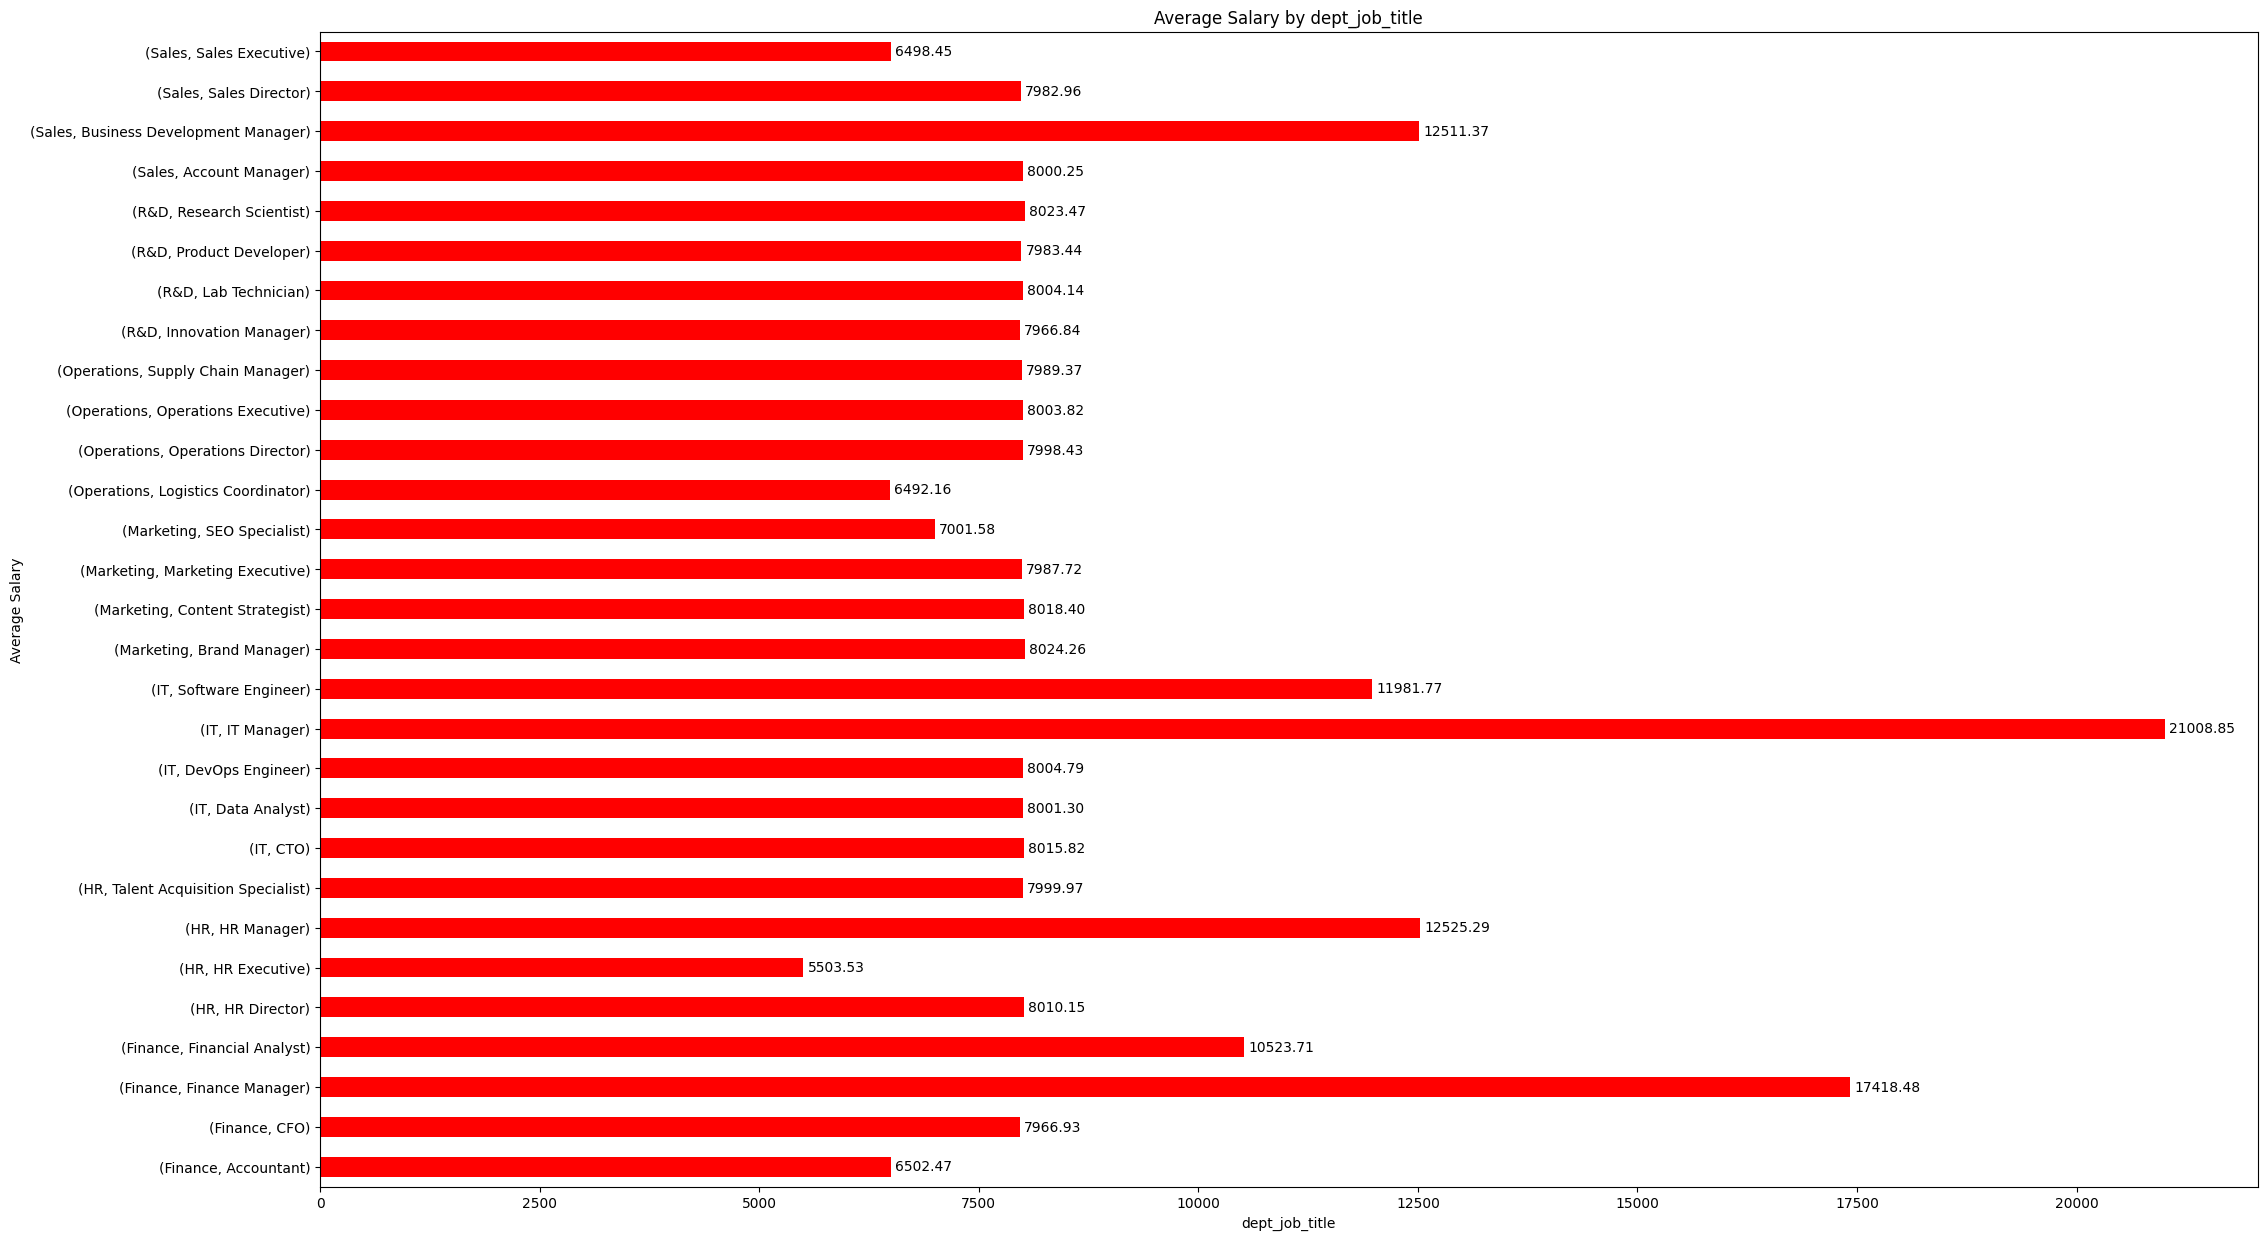

In [147]:
ax = dept_job_title.plot(
    kind="barh",
    color="r",
    figsize=(25,15)
)

# Add data labels
ax.bar_label(
    ax.containers[0],
    fmt="%.2f",
    padding=3,
    fontsize=10)

plt.title("Average Salary by dept_job_title")
plt.xlabel("dept_job_title")
plt.ylabel("Average Salary")
plt.show()

In [148]:
# Q.7) How many employees Resigned & Terminated in each department?
df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [157]:
exit_df = df[df['Status'].isin(['Resigned', 'Terminated'])]

dept_exit = exit_df.groupby('Department')['Status'].count()
dept_exit


,Status
Department,
Finance,26285
HR,20805
IT,78690
Marketing,31279
Operations,39067
R&D,13106
Sales,52442


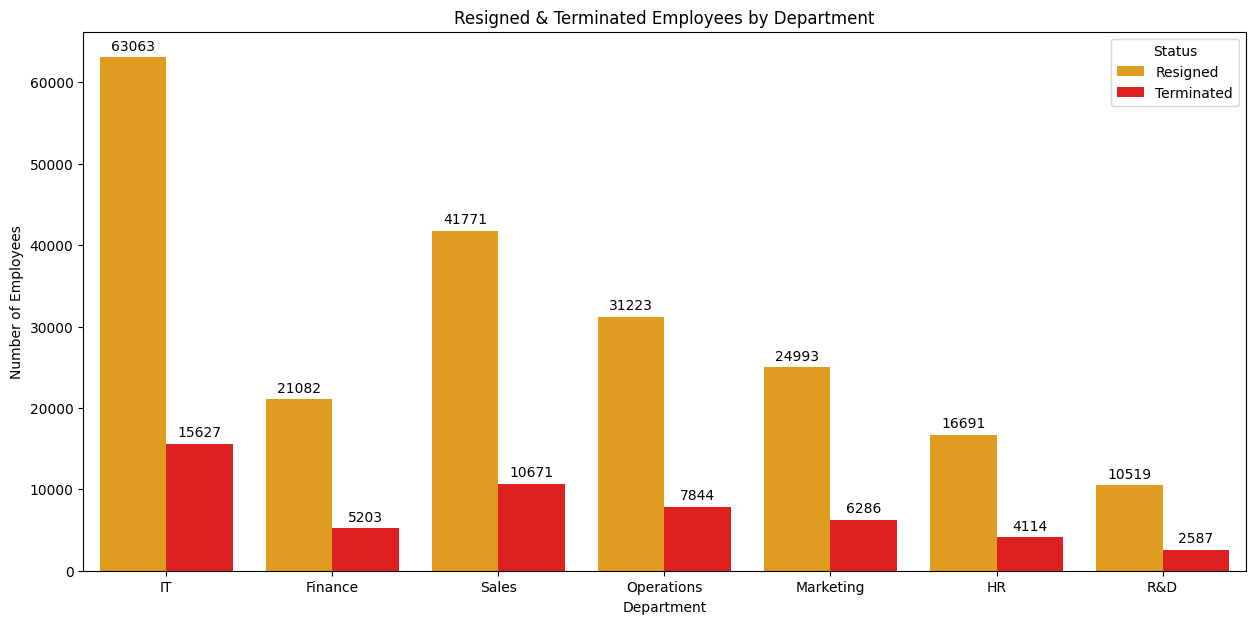

In [156]:
plt.figure(figsize=(15, 7))

ax = sns.countplot(
    data=exit_df,
    x='Department',
    hue='Status',
    palette=['orange', 'red']
)

# Add data labels
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=10)

plt.title('Resigned & Terminated Employees by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.show()

In [160]:
#Q.9) What is the average performance rating by department?

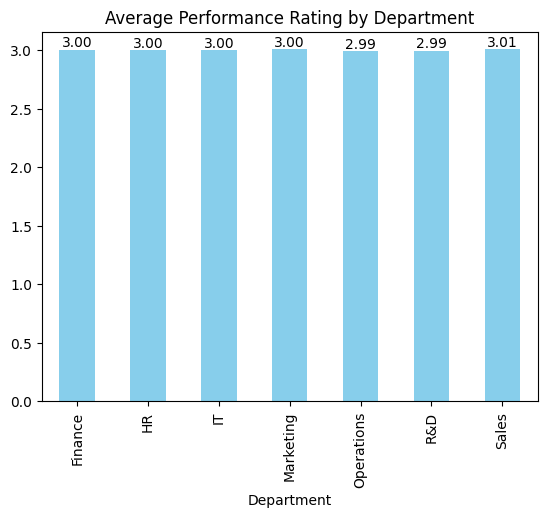

In [165]:
dept_rating = df.groupby('Department')['Performance_Rating'].mean()

ax = dept_rating.plot(kind='bar', color='skyblue')

ax.bar_label(ax.containers[0], fmt='%.2f')

plt.title('Average Performance Rating by Department')
plt.show()

In [168]:
#Q.10) Which Country have the highest concentration of employees?
df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686


In [171]:
df['Country']=df['Location'].apply(lambda x:str(x.split(',')[0]))

df.head(2)

,Employee_ID,Full_Name,Department,Job_Title,Hire_Date,Location,Performance_Rating,Experience_Years,Status,Work_Mode,Salary_INR,Country
0,EMP0000001,Joshua Nguyen,IT,Software Engineer,2011-08-10,"Isaacland, Denmark",5,14,Resigned,On-site,1585363,Isaacland
1,EMP0000002,Julie Williams,Marketing,SEO Specialist,2018-03-02,"Anthonyside, Costa Rica",2,7,Active,On-site,847686,Anthonyside


In [178]:
df['Country'].value_counts()

,count
Country,
Port Michael,893
Lake Michael,875
East Michael,851
South Michael,829
North Michael,823
...,...
New Traceyfurt,1
New Meghanbury,1
New Isaactown,1


In [182]:
# Q.12) How has the number of hires changed over time (per year)?

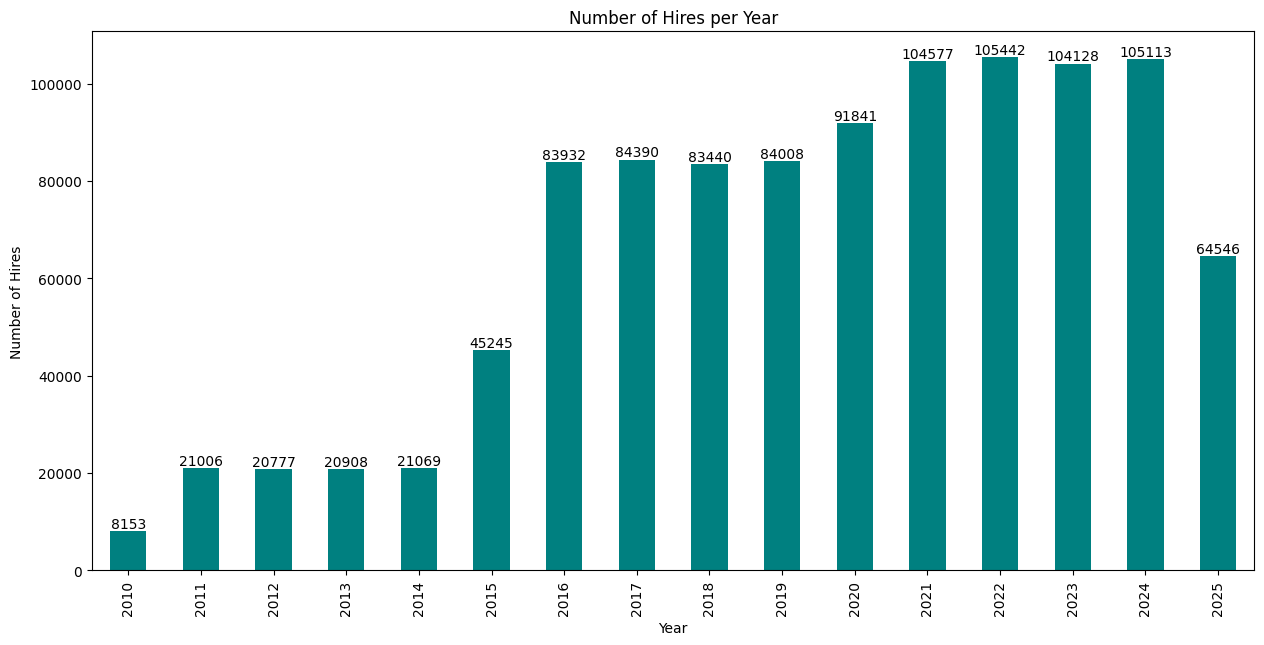

In [181]:
plt.figure(figsize=(15, 7))

yearly_hires = df['Hire_Date'].dt.year.value_counts().sort_index()

ax = yearly_hires.plot(kind='bar', color='teal')

ax.bar_label(ax.containers[0])

plt.title('Number of Hires per Year')
plt.xlabel('Year')
plt.ylabel('Number of Hires')
plt.show()

In [190]:
# Q.13) Compare AVG salaries of Remote vs. On-site employees
print(df.groupby('Work_Mode')['Salary_INR'].mean()/100)

Work_Mode
On-site    8970.496783
Remote     8966.441123
Name: Salary_INR, dtype: float64


In [196]:
# Top 5 highest salaries in each department
top_10 = df.groupby('Department').apply(
    lambda x: x.nlargest(5, 'Salary_INR')
)

print(top_10[['Department', 'Salary_INR']])

                    Department  Salary_INR
Department                                
Finance    888712      Finance     2499958
           695808      Finance     2499929
           459273      Finance     2499925
           750893      Finance     2499813
           780290      Finance     2499786
HR         223845           HR     1799839
           553718           HR     1799728
           674999           HR     1799705
           230232           HR     1799625
           455642           HR     1799534
IT         645146           IT     2999889
           766571           IT     2999881
           369339           IT     2999797
           403844           IT     2999718
           220124           IT     2999671
Marketing  1015129   Marketing     1199995
           373011    Marketing     1199988
           158254    Marketing     1199971
           814806    Marketing     1199959
           982288    Marketing     1199943
Operations 61771    Operations     1199991
           

/tmp/ipykernel_6475/1958690456.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_10 = df.groupby('Department').apply(


In [199]:
# Attrition rate by department
attrition = df.groupby('Department')['Status'].apply(
    lambda x: (x == 'Resigned').mean() * 100
)

print(attrition.sort_values(ascending=False))

Department
R&D           20.154816
Finance       20.131396
IT            20.018221
HR            19.993053
Sales         19.936141
Operations    19.822491
Marketing     19.817941
Name: Status, dtype: float64
